# Aplicaciones del Aprendizaje Automático

En este cuaderno veremos algunos ejemplos sencillos relacionados con las series temporales, los sistemas recomendadores y el PLN en Python. El objetivo de estos ejemplos es ilustrar cómo se puede iniciar la aplicación del AA en estos 3 ámbitos, aunque no abordaremos casos de uso demasiados complejos.

## 1. Análisis de series temporales

En primer lugar, veamos cómo podemos descomponer y modelizar una serie temporal utilizando la librería `statsmodels`.

Para ello, vamos a emplear un conjunto de datos con mediciones de la concentración de CO2 atmosférica en diferentes estaciones meteorológicas a lo largo de los años, desde 1958 hasta 2001.

In [1]:
# Importamos las librerías
import statsmodels.api as sm
import matplotlib.pyplot as plt
%matplotlib inline

# Cargamos los datos
data = sm.datasets.co2.load_pandas().data
data.head(10)

,co2
1958-03-29,316.1
1958-04-05,317.3
1958-04-12,317.6
1958-04-19,317.5
1958-04-26,316.4
1958-05-03,316.9
1958-05-10,NaN
1958-05-17,317.5
1958-05-24,317.9
1958-05-31,NaN


Para facilitar el análisis, vamos a considerar solo los valores medios mensuales para así obtener una serie temporal con datos equiespaciados en el tiempo. Adicionalmente, si para algún mes no hay registros, utilizaremos los datos del mes anterior.

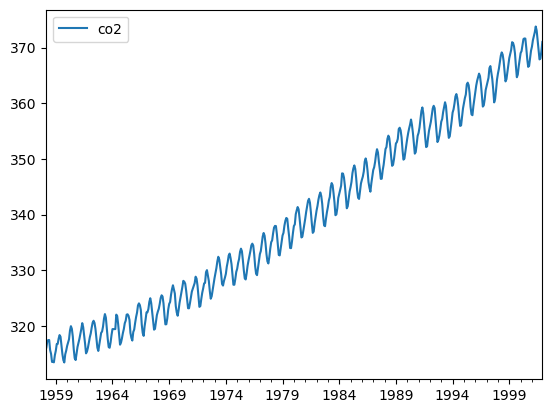

In [2]:
# Calcular la media por mes y rellenar posibles nulos
data_monthly = data.resample('M').mean().ffill()

# Visualizamos la serie completa
data_monthly.plot()
plt.show()

Una vez hemos procesado la serie temporal, vamos a descomponerla para poder observar cada una de sus componentes. Esto es casi inmediato utilizando `statsmodels`.

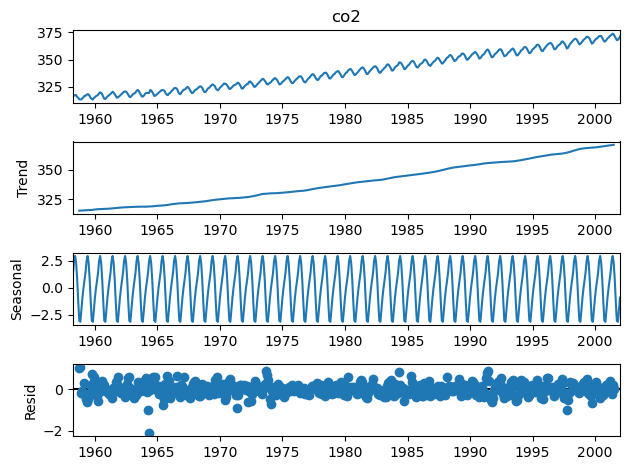

In [3]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Descomposición aditiva
resultado = seasonal_decompose(data_monthly['co2'], model='additive')

# Representamos cada componente
resultado.plot()
plt.tight_layout()
plt.show()

Observamos una tendencia creciente y un patrón estacional muy marcado. Los residuos parecen pequeños, lo cual es un buen indicador de que la descomposición es correcta.

Otro de los gráficos que podemos obtener es el de la autocorrelación parcial. Esto nos dará información útil sobre el período de la serie y el número de lags más relevante de cara al forecast.

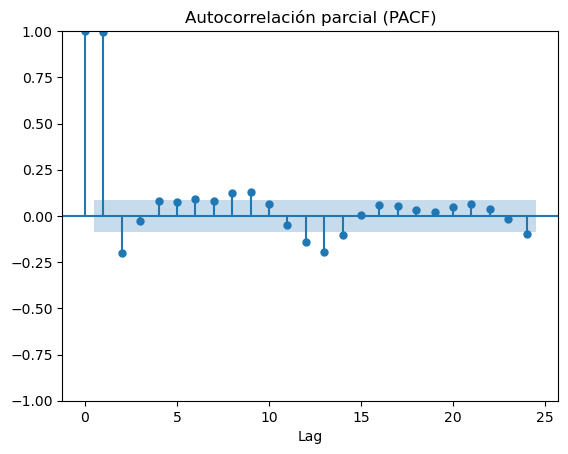

In [4]:
from statsmodels.graphics.tsaplots import plot_pacf

plot_pacf(data_monthly['co2'], lags=24, method='ywm')
plt.title("Autocorrelación parcial (PACF)")
plt.xlabel('Lag')
plt.show()

Como vemos, los lags más relevantes son el 1 (es decir, el mes anterior) y los que se sitúan en torno a 6 y a 12. Parece claro que existe un patrón anual, lo cual ya habíamos visto en su descomposición.

Finalmente, vamos a tratar de hacer un forecast utilizando un modelo ARIMA. Ajustaremos el modelo con toda la serie excepto los últimos 5 años, los cuales utilizaremos para evaluar y medir el error absoluto medio.

Para entrenar el modelo ARIMA, necesitamos elegir el orden (p, q, d) del modelo. Estos parámetros son especialmente sensibles, y una mala elección de los mismos puede dar lugar a resultados muy malos. En este caso vamos a utilizar (12, 2, 3).

/Users/jajimer/miniconda3/envs/uax/lib/python3.9/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Users/jajimer/miniconda3/envs/uax/lib/python3.9/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/Users/jajimer/miniconda3/envs/uax/lib/python3.9/site-packages/statsmodels/base/model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


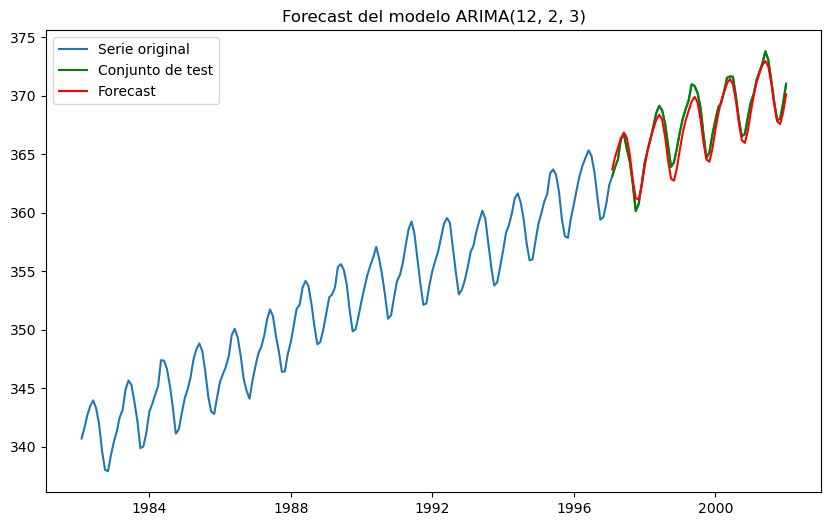

Mean Absolute Error: 0.6459178067834604


In [15]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error

# Meses a considerar en el conjunto de test
n_steps = 5 * 12

# Dividimos la serie en train y test
train_size = len(data_monthly) - n_steps
train, test = data_monthly['co2'][:train_size], data_monthly['co2'][train_size:]

# Ajustamos el modelo ARIMA
model = ARIMA(train, order=(12, 2, 3))
fitted_model = model.fit()

# Forecast de los últimos 5 años
forecast = fitted_model.forecast(steps=n_steps)
forecast_index = test.index

# Visualizamos los resultados
years_to_plot = 20

plt.figure(figsize=(10, 6))
plt.plot(data_monthly['co2'].tail(years_to_plot * 12), label='Serie original')
plt.plot(test.index, test, label='Conjunto de test', color='green')
plt.plot(forecast_index, forecast, label='Forecast', color='red')
plt.legend()
plt.title('Forecast del modelo ARIMA(12, 2, 3)')
plt.show()

# Evaluación del modelo
mae = mean_absolute_error(test, forecast)
print(f'Mean Absolute Error: {mae}')

¡No está nada mal! Vemos que el modelo ha capturado correctamente la tendencia y el patrón estacional, obteniendo un MAE en el conjunto de test de 0.65. Ajustando el orden del modelo ARIMA se podrían obtener resultados aún mejores.

## 2. Sistemas recomendadores

En esta sección vamos a crear una implementación sencilla de un sistema recomendador, en concreto de un filtro colaborativo. El objetivo aquí es ilustrar cómo podemos generar recomendaciones utilizando únicamente la matriz de utilidad, sin necesidad de algoritmos complejos.

Para hacerlo, vamos a crear un conjunto de datos simple con 20 usuarios y 30 ítems. Los ratings varían entre 1 y 5. Y vamos a asumir que hay un 20% de espacios en blanco en esta matriz.

In [6]:
import pandas as pd
import numpy as np

# Semilla aleatoria para reproducibilidad
np.random.seed(42)

# Definir usuarios e items
n_users = 20
n_items = 30
users = [f'user_{i}' for i in range(1, n_users+1)]
items = [f'item_{j}' for j in range(1, n_items+1)]

# Generamos ratings aleatorios entre 1 y 5
ratings = np.random.randint(1, 6, size=(len(users), len(items)))

# Creamos el dataframe con los usuarios en las filas y los items en las columnas
df = pd.DataFrame(ratings, index=users, columns=items)

# Finalmente, introducimos un 20% de registros NaN (usuarios que no han interactuado con esos items)
p_nan = 0.2
nan_indices = np.random.choice(df.size, int(p_nan * df.size), replace=False)

for index in np.ndindex(df.shape):
    if np.ravel_multi_index(index, df.shape) in nan_indices:
        df.iloc[index] = np.nan
        
df.head(10)

,item_1,item_2,item_3,item_4,item_5,item_6,item_7,item_8,item_9,item_10,...,item_21,item_22,item_23,item_24,item_25,item_26,item_27,item_28,item_29,item_30
user_1,4.0,NaN,3.0,5.0,5.0,2.0,3.0,3.0,NaN,5.0,...,2.0,5.0,4.0,NaN,1.0,3.0,3.0,2.0,4.0,4.0
user_2,3.0,4.0,4.0,1.0,3.0,5.0,3.0,5.0,1.0,2.0,...,4.0,NaN,4.0,5.0,NaN,1.0,NaN,NaN,NaN,2.0
user_3,2.0,4.0,5.0,NaN,2.0,4.0,2.0,2.0,4.0,4.0,...,5.0,NaN,5.0,5.0,1.0,1.0,NaN,NaN,4.0,3.0
user_4,NaN,1.0,3.0,3.0,1.0,NaN,5.0,2.0,2.0,1.0,...,1.0,3.0,5.0,NaN,1.0,NaN,NaN,3.0,1.0,2.0
user_5,2.0,4.0,5.0,NaN,1.0,4.0,5.0,NaN,NaN,5.0,...,1.0,5.0,4.0,NaN,4.0,4.0,NaN,3.0,NaN,4.0
user_6,1.0,1.0,1.0,1.0,3.0,NaN,4.0,5.0,1.0,3.0,...,NaN,1.0,2.0,4.0,NaN,NaN,3.0,1.0,5.0,1.0
user_7,NaN,3.0,1.0,2.0,2.0,NaN,5.0,1.0,NaN,3.0,...,2.0,3.0,1.0,1.0,4.0,3.0,5.0,NaN,4.0,NaN
user_8,NaN,4.0,3.0,2.0,3.0,3.0,4.0,4.0,1.0,1.0,...,2.0,1.0,4.0,NaN,1.0,2.0,1.0,4.0,5.0,5.0
user_9,3.0,1.0,1.0,NaN,NaN,NaN,4.0,1.0,4.0,3.0,...,2.0,3.0,5.0,1.0,4.0,NaN,4.0,1.0,5.0,NaN
user_10,3.0,NaN,1.0,4.0,3.0,3.0,5.0,3.0,3.0,3.0,...,NaN,1.0,1.0,4.0,4.0,5.0,5.0,3.0,4.0,1.0


Ahora comenzamos a implementar nuestro filtro colaborativo de andar por casa. El primer paso es calcular la similitud entre cada usuario, en base a sus ratings. Para ello, podemos utilizar la función de numpy `cosine_similarity`.

En este caso, necesitamos que los vectores de ratings no tengan nulos, así que vamos a imputarlos con la media.

In [7]:
from sklearn.metrics.pairwise import cosine_similarity

df_filled = df.apply(lambda row: row.fillna(row.mean()), axis=1)

similarities = cosine_similarity(df_filled)
user_similarity_df = pd.DataFrame(similarities, index=users, columns=users)
user_similarity_df

,user_1,user_2,user_3,user_4,user_5,user_6,user_7,user_8,user_9,user_10,user_11,user_12,user_13,user_14,user_15,user_16,user_17,user_18,user_19,user_20
user_1,1.000000,0.873565,0.928266,0.887809,0.919274,0.868354,0.879190,0.859559,0.876713,0.867818,0.892464,0.886821,0.913896,0.891697,0.884350,0.927953,0.841199,0.919981,0.863334,0.893011
user_2,0.873565,1.000000,0.911107,0.837479,0.869161,0.888144,0.797133,0.891927,0.806391,0.821541,0.850403,0.779133,0.849854,0.858377,0.837326,0.845785,0.839042,0.864849,0.869361,0.831674
user_3,0.928266,0.911107,1.000000,0.857748,0.907486,0.847172,0.853926,0.841224,0.843466,0.836682,0.872462,0.831677,0.866424,0.894845,0.817856,0.850719,0.921826,0.861518,0.858295,0.866125
user_4,0.887809,0.837479,0.857748,1.000000,0.897379,0.804914,0.839118,0.827975,0.845344,0.858625,0.776157,0.778828,0.824686,0.852577,0.792013,0.823365,0.813583,0.859556,0.877489,0.849288
user_5,0.919274,0.869161,0.907486,0.897379,1.000000,0.856155,0.903158,0.868037,0.868690,0.897084,0.871822,0.875083,0.935980,0.896504,0.866205,0.908480,0.875781,0.890522,0.895653,0.880907
user_6,0.868354,0.888144,0.847172,0.804914,0.856155,1.000000,0.853608,0.835888,0.824633,0.888349,0.833814,0.784549,0.833830,0.848989,0.793605,0.858131,0.803902,0.872516,0.875156,0.843410
user_7,0.879190,0.797133,0.853926,0.839118,0.903158,0.853608,1.000000,0.800006,0.865135,0.914078,0.865535,0.839509,0.898207,0.829956,0.819212,0.846262,0.838141,0.868998,0.839163,0.878239
user_8,0.859559,0.891927,0.841224,0.827975,0.868037,0.835888,0.800006,1.000000,0.794552,0.815358,0.816604,0.831669,0.790424,0.878933,0.741413,0.861733,0.809017,0.859680,0.853894,0.818179
user_9,0.876713,0.806391,0.843466,0.845344,0.868690,0.824633,0.865135,0.794552,1.000000,0.877313,0.834201,0.768097,0.819230,0.853874,0.819848,0.868588,0.825340,0.783297,0.848800,0.870829
user_10,0.867818,0.821541,0.836682,0.858625,0.897084,0.888349,0.914078,0.815358,0.877313,1.000000,0.878992,0.863231,0.893824,0.856359,0.822806,0.878897,0.847762,0.878435,0.875055,0.856364


Esta matriz nos indica la similitud entre usuarios, y puede ir de -1 (muy poco similares) a 1 (muy similares). Por ejemplo, vemos que el usuario más similar al usuario 1 es el usuario 3.

Con esta matriz ya podemos implementar nuestro algoritmo, para lo cual utilizamos la siguiente función. Vamos a generar 3 recomendaciones para cada usuario de los items con los que no ha interactuado. Para predecir esos ratings, vamos a utilizar una media ponderada de los ratings de otros usuarios, utilizando la similitud entre ellos.

In [8]:
def filtro_colaborativo(user, df, similarity_matrix, top_n=3):
    # Ratings del usuario
    user_ratings = df.loc[user]
    # Obtener items sin ratings
    unrated_items = user_ratings[user_ratings.isna()].index
    # Calculamos el rating medio predicho en base a la similitud con otros usuarios
    pred_ratings = {}
    for item in unrated_items:
        suma_ponderada = 0
        suma_similitud = 0
        # Iteramos por los usuarios distintos al usuario objetivo
        for other_user in users:
            if pd.notna(df.loc[other_user, item]) and other_user != user:
                suma_ponderada += similarity_matrix.loc[user, other_user] * df.loc[other_user, item]
                suma_similitud += similarity_matrix.loc[user, other_user]
        # Calculamos el rating y lo guardamos
        pred_ratings[item] = suma_ponderada / suma_similitud if suma_similitud > 0 else 0

    # Finalmente, recomendamos los N items con mayor ranking predicho
    recommended_items = sorted(pred_ratings, key=pred_ratings.get, reverse=True)[:top_n]
    return recommended_items

Y ahora, lo aplicamos a nuestro dataset:

In [9]:
recommendations = {user: filtro_colaborativo(user, df, user_similarity_df) for user in users}

# Display recommendations for each user
for user, items in recommendations.items():
    print(f"Recomendaciones para el usuario {user}: {items}")

Recomendaciones para el usuario user_1: ['item_24', 'item_16', 'item_2']
Recomendaciones para el usuario user_2: ['item_20', 'item_29', 'item_27']
Recomendaciones para el usuario user_3: ['item_20', 'item_27', 'item_4']
Recomendaciones para el usuario user_4: ['item_24', 'item_6', 'item_27']
Recomendaciones para el usuario user_5: ['item_24', 'item_29', 'item_27']
Recomendaciones para el usuario user_6: ['item_6', 'item_12', 'item_13']
Recomendaciones para el usuario user_7: ['item_6', 'item_13', 'item_30']
Recomendaciones para el usuario user_8: ['item_24', 'item_1']
Recomendaciones para el usuario user_9: ['item_6', 'item_30', 'item_4']
Recomendaciones para el usuario user_10: ['item_13', 'item_2', 'item_18']
Recomendaciones para el usuario user_11: ['item_24', 'item_29', 'item_7']
Recomendaciones para el usuario user_12: ['item_24', 'item_27', 'item_26']
Recomendaciones para el usuario user_13: ['item_24', 'item_6', 'item_27']
Recomendaciones para el usuario user_14: ['item_7', 'ite

De esta forma, es posible generar recomendaciones personalizadas para cada usuario.

Como vimos en clase, este tipo de sistemas es particularmente útil cuando existen una gran cantidad de usuarios e items. También debemos tener en cuenta que esta es una implementación sencilla, y que en entornos reales es necesario tener en cuenta otra serie de consideraciones (problema del arranque frío, adaptación ante nuevos datos, etc.).

## 3. Procesamiento de Lenguaje Natural (PLN)

Finalmente, vamos a utilizar sklearn para transformar un conjunto de datos con textos en una representación vectorial. Con ello, ya podremos utilizar otro tipo de algoritmos de AA.

Para ilustrar este ejemplo, vamos a utilizar un dataset con textos de blogs de diferentes temas (en inglés). Para simplificar un poco el conjunto de datos vamos a eliminar metadatos del blog (indicando con el parámetro `remove`) y a quedarnos solo con 3 categorías.

In [10]:
from sklearn.datasets import fetch_20newsgroups

# Categorías elegidas
categorias = ['sci.space', 'rec.sport.baseball', 'comp.graphics']

data, targets = fetch_20newsgroups(return_X_y=True, remove=('headers', 'footers', 'quotes'), categories=categorias)

print(f"Número de documentos: {len(data)}")

# Documento de ejemplo
print(f"\nEjemplo:\n{data[0]}")
print(f"\nCategoría: {targets[0]}")

Número de documentos: 1774

Ejemplo:

By '8 grey level images' you mean 8 items of 1bit images?
It does work(!), but it doesn't work if you have more than 1bit
in your screen and if the screen intensity is non-linear.

With 2 bit per pixel; there could be 1*c_1 + 4*c_2 timing,
this gives 16 levels, but they are linear if screen intensity is
linear.
With 1*c_1 + 2*c_2 it works, but we have to find the best
compinations -- there's 10 levels, but 16 choises; best 10 must be
chosen. Different compinations for the same level, varies a bit, but
the levels keeps their order.

Readers should verify what I wrote... :-)

Categoría: 0


A continuación vamos a implementar la codificación TF-IDF, la cual está implementada en la clase `TfidfVectorizer` de sklearn.

Vamos a pasarle algunos parámetros adicionales:
 - Eliminaremos stopwords, es decir, palabras que no aportan significado léxico.
 - Nos quedaremos con un máximo de 500 palabras.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(stop_words='english', max_features=500)

# Lo ajustamos y transformamos el conjunto de datos
X_tfidf = vectorizer.fit_transform(data)

In [12]:
# Mostramos algunas de las palabras capturadas
vectorizer.get_feature_names_out()[:100]

array(['00', '000', '01', '02', '03', '04', '05', '10', '100', '11', '12',
       '128', '13', '14', '15', '16', '17', '18', '19', '1992', '1993',
       '20', '200', '21', '22', '23', '24', '25', '256', '28', '30',
       '300', '35', '3d', '40', '400', '50', '500', '90', '92', '93',
       'able', 'access', 'actually', 'add', 'address', 'advance', 'ago',
       'air', 'al', 'algorithm', 'alomar', 'american', 'ames', 'amiga',
       'analysis', 'animation', 'anonymous', 'answer', 'anybody',
       'applications', 'april', 'archive', 'area', 'aren', 'article',
       'astronomy', 'atmosphere', 'author', 'available', 'average',
       'away', 'bad', 'ball', 'base', 'baseball', 'based', 'believe',
       'best', 'better', 'big', 'billion', 'bit', 'black', 'book',
       'books', 'box', 'braves', 'build', 'built', 'ca', 'called', 'card',
       'career', 'case', 'center', 'certainly', 'change', 'check',
       'close'], dtype=object)

In [13]:
# Tamaño del dataset resultante
print(X_tfidf.shape)

(1774, 500)


De esta forma, hemos pasado de un conjunto de textos a una matriz de 500 columnas, la cual ya podemos utilizar en nuestros algoritmos de ML.

Por último, veamos qué ocurre al entrenar un clasificador para predecir la categoría de los blogs.

In [14]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(SVC(), X_tfidf, targets, scoring = 'accuracy')
print('Accuracy medio CV: ', cv_scores.mean())

Accuracy medio CV:  0.8545699053075516


¡Not bad! Incluso con una representación sencilla del texto, hemos conseguido un accuracy medio del 85% a la hora de predecir la categoría de los blogs. Esto se debe, en parte, a que la presencia o ausencia de ciertas palabras es muy significativa a la hora de clasificar un texto.